# Data Visualization — Mix Dataset (PoI, 306 features)

Exploratory visualization of the raw electropherogram (EPG) signal data used throughout
this project, in the same spirit as the earlier `LTDNA_MLtoPeak.ipynb` exploration, but
cleaned up, self-contained (no Colab-specific installs or paths), and tied back to the
paper's own findings — the x-axis positions used here are the same UpStream/DownStream
indices referenced in the SHAP analysis.

**Dataset**: `Input_Data-Mix-train.csv` — 426 labelled peaks from two-person mixture
EPGs, 306 features (305 positional/cross-channel signal features + the retained `PoI`
feature).

**Signal layout**: each row's *primary-channel* trace is `UpStream_100 ... UpStream_1,
[signal of interest], DownStream_1 ... DownStream_100` — 200 points centred on the peak
being classified. `C1`–`C5` are five additional fluorescence channels, each contributing
its own 21-point local context (10 upstream + the channel value at the SoI + 10
downstream) — this is the cross-channel information the paper's SHAP analysis found
relevant specifically for Pull-Up classification (channel bleed-through).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import rfft, rfftfreq

_cwd = os.getcwd()
ROOT = _cwd
for _c in [_cwd] + [os.path.abspath(os.path.join(_cwd, *['..'] * i)) for i in range(1, 4)]:
    if os.path.isfile(os.path.join(_c, 'Input_Data-Mix-train.csv')):
        ROOT = _c
        break

sys.path.insert(0, os.path.join(ROOT, 'scripts'))
from model_colors import MODEL_COLORS

FIG_DIR = os.path.join(ROOT, 'Mix_Results_PoI', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

%matplotlib inline
plt.rcParams.update({'figure.dpi': 130, 'font.family': 'sans-serif'})

CLASS_ORDER  = ['Allele', 'Back_Stutter', 'Forward_Stutter', 'Pull_Up']
CLASS_LABELS = {'Allele': 'Allele', 'Back_Stutter': 'Back Stutter',
                'Forward_Stutter': 'Forward Stutter', 'Pull_Up': 'Pull-Up'}
CLASS_COLORS = {'Allele': '#1565C0', 'Back_Stutter': '#2E7D32',
                'Forward_Stutter': '#C62828', 'Pull_Up': '#E65100'}

df = pd.read_csv(os.path.join(ROOT, 'Input_Data-Mix-train.csv'))
print('Project root:', ROOT)
print('Shape:', df.shape)
df.head(3)

Project root: c:\Users\DT User\Documents\GitHub\ML_in_LTDNA
Shape: (426, 308)


,sample,PoI,C1_UpStream_1,C1_UpStream_2,C1_UpStream_3,C1_UpStream_4,C1_UpStream_5,C1_UpStream_6,C1_UpStream_7,C1_UpStream_8,...,DownStream_92,DownStream_93,DownStream_94,DownStream_95,DownStream_96,DownStream_97,DownStream_98,DownStream_99,DownStream_100,Classification
0,B-Allele-4251,16666.40631,-403.436291,-380.196206,-366.252155,-390.654244,-390.654244,-411.570321,-447.011451,-447.011451,...,-171.035439,-89.114138,29.410297,242.928580,796.333109,1371.525219,1929.287264,2539.339502,3016.487502,Allele
1,B-Allele-4301,16582.16100,-418.542346,-380.196206,-372.933679,-372.933679,-399.805028,-429.581387,-429.581387,-467.346525,...,-258.185758,-258.185758,-237.850684,-237.850684,-214.610598,-205.895566,-205.895566,-205.895566,-205.895566,Allele
2,B-Allele-4352,3176.98934,-397.626270,-369.738167,-369.738167,-380.196206,-423.771366,-423.771366,-432.486397,-449.916461,...,-258.185758,-246.565716,-255.280748,-255.280748,-232.040662,-236.398178,-258.185758,-258.185758,-258.185758,Allele


## 1  Dataset overview

In [2]:
print(f"Samples: {len(df)}   Columns: {df.shape[1]}   Missing values: {df.isnull().sum().sum()}")
print(f"\nNon-signal columns: sample, PoI, Classification")
signal_cols_primary = [c for c in df.columns if ('Stream' in c) and not c.startswith(('C1', 'C2', 'C3', 'C4', 'C5'))]
cross_channel_cols  = [c for c in df.columns if c.startswith(('C1', 'C2', 'C3', 'C4', 'C5'))]
print(f"Primary-channel signal columns (UpStream/DownStream): {len(signal_cols_primary)}")
print(f"Cross-channel (C1-C5) columns: {len(cross_channel_cols)}")
print(f"Total signal features (+PoI): {len(signal_cols_primary) + len(cross_channel_cols) + 1}")

fig, ax = plt.subplots(figsize=(7, 4.5))
counts = df['Classification'].value_counts().reindex(CLASS_ORDER)
bars = ax.bar([CLASS_LABELS[c] for c in CLASS_ORDER], counts.values,
              color=[CLASS_COLORS[c] for c in CLASS_ORDER], edgecolor='white')
for bar, count in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, count + 3, str(count), ha='center', fontsize=10)
ax.set_ylabel('Count', fontsize=10.5)
ax.set_title(f'Class distribution — Mix dataset (n={len(df)})', fontsize=11.5)
ax.grid(axis='y', linestyle='--', alpha=0.35)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_class_distribution.png'), dpi=200, bbox_inches='tight')
plt.show()

Samples: 426   Columns: 308   Missing values: 0

Non-signal columns: sample, PoI, Classification
Primary-channel signal columns (UpStream/DownStream): 200
Cross-channel (C1-C5) columns: 105
Total signal features (+PoI): 306


RecursionError: maximum recursion depth exceeded

Error in callback <function _draw_all_if_interactive at 0x000001CEFD401B10> (for post_execute), with arguments args (),kwargs {}:


RecursionError: maximum recursion depth exceeded

RecursionError: maximum recursion depth exceeded

<Figure size 910x585 with 1 Axes>

## 2  One example trace per class (primary channel)

X-axis is position relative to the signal of interest (SoI, position 0) — upstream
positions are negative, downstream positive, matching how the paper's SHAP features
(e.g. `UpStream_95`, `DownStream_47`) are indexed.

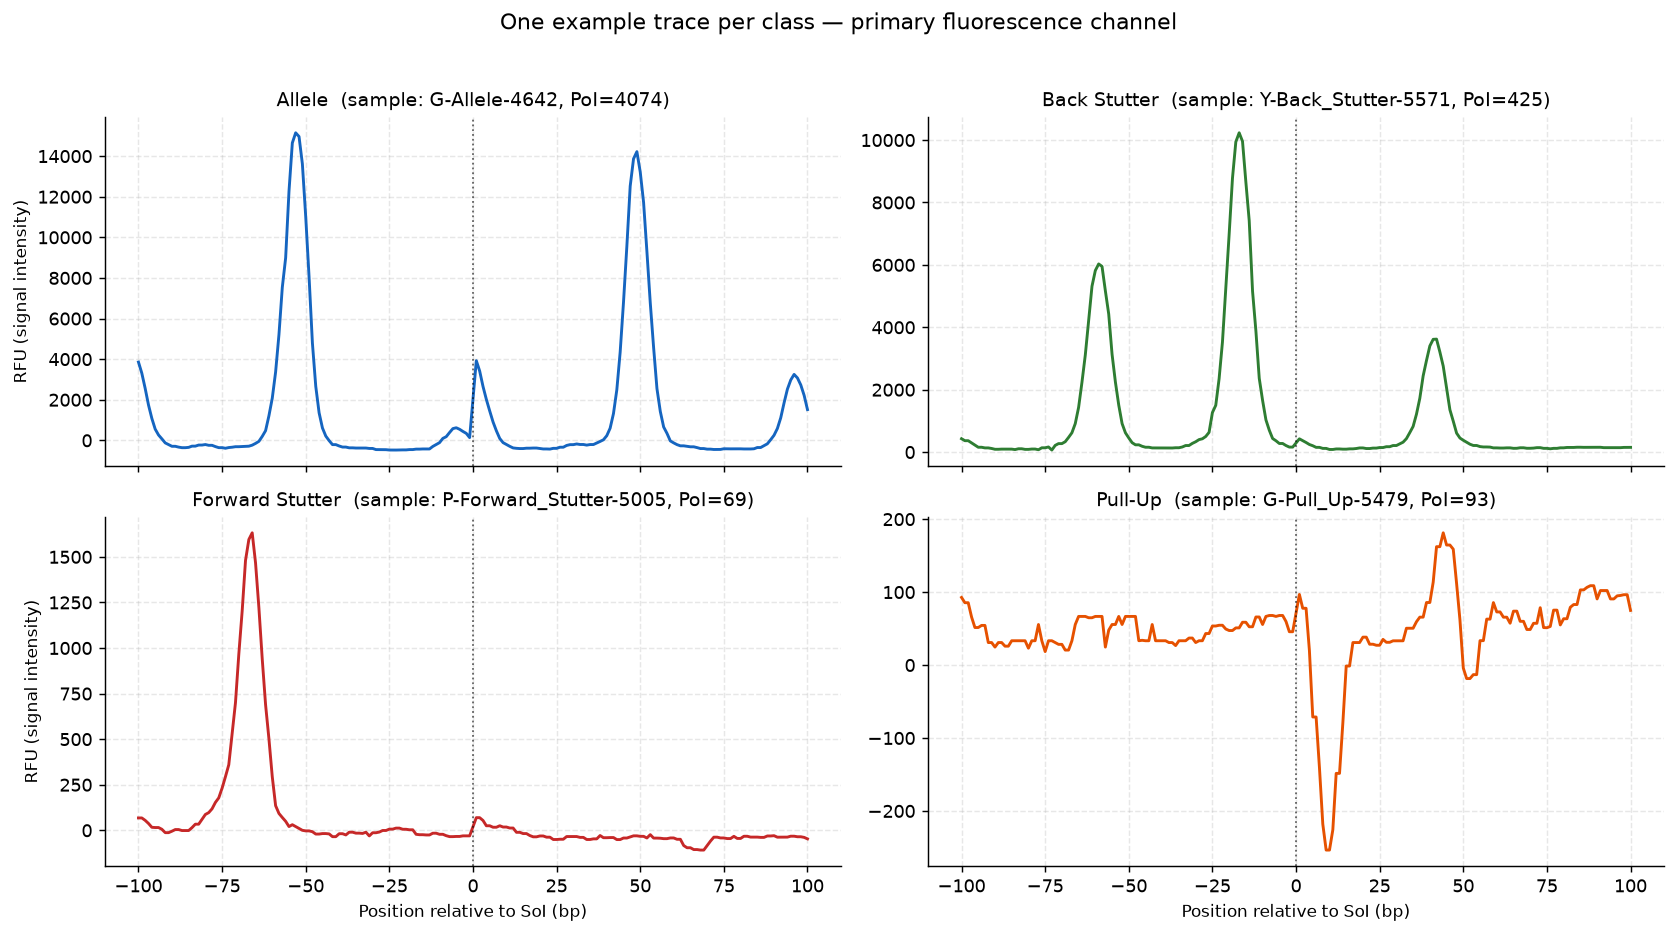

In [ ]:
up_cols   = [f'UpStream_{i}' for i in range(100, 0, -1)]     # far -> near
down_cols = [f'DownStream_{i}' for i in range(1, 101)]        # near -> far
x_positions = list(range(-100, 0)) + [0] + list(range(1, 101))  # -100..-1, SoI, 1..100

def primary_trace(row):
    """Full primary-channel trace, SoI value taken as the max of the two flanking points
    (the dataset does not store a separate 'SoI' column for the primary channel; we
    interpolate it for display continuity only — classification itself never uses this
    interpolated point)."""
    up = row[up_cols].values.astype(float)
    down = row[down_cols].values.astype(float)
    soi_display = (up[-1] + down[0]) / 2
    return np.concatenate([up, [soi_display], down])

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
rng = np.random.default_rng(42)

for ax, cls in zip(axes.flat, CLASS_ORDER):
    sub = df[df['Classification'] == cls]
    row = sub.sample(1, random_state=42).iloc[0]
    trace = primary_trace(row)
    ax.plot(x_positions, trace, color=CLASS_COLORS[cls], linewidth=1.6)
    ax.axvline(0, color='k', linestyle=':', linewidth=1, alpha=0.6, label='Signal of interest')
    ax.set_title(f"{CLASS_LABELS[cls]}  (sample: {row['sample']}, PoI={row['PoI']:.0f})", fontsize=10.5)
    ax.grid(linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

for ax in axes[1]:
    ax.set_xlabel('Position relative to SoI (bp)', fontsize=9.5)
for ax in axes[:, 0]:
    ax.set_ylabel('RFU (signal intensity)', fontsize=9.5)

plt.suptitle('One example trace per class — primary fluorescence channel', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_example_trace_per_class.png'), dpi=200, bbox_inches='tight')
plt.show()

## 3  Multiple examples per class

Four random instances per class, overlaid, to show within-class shape variability.

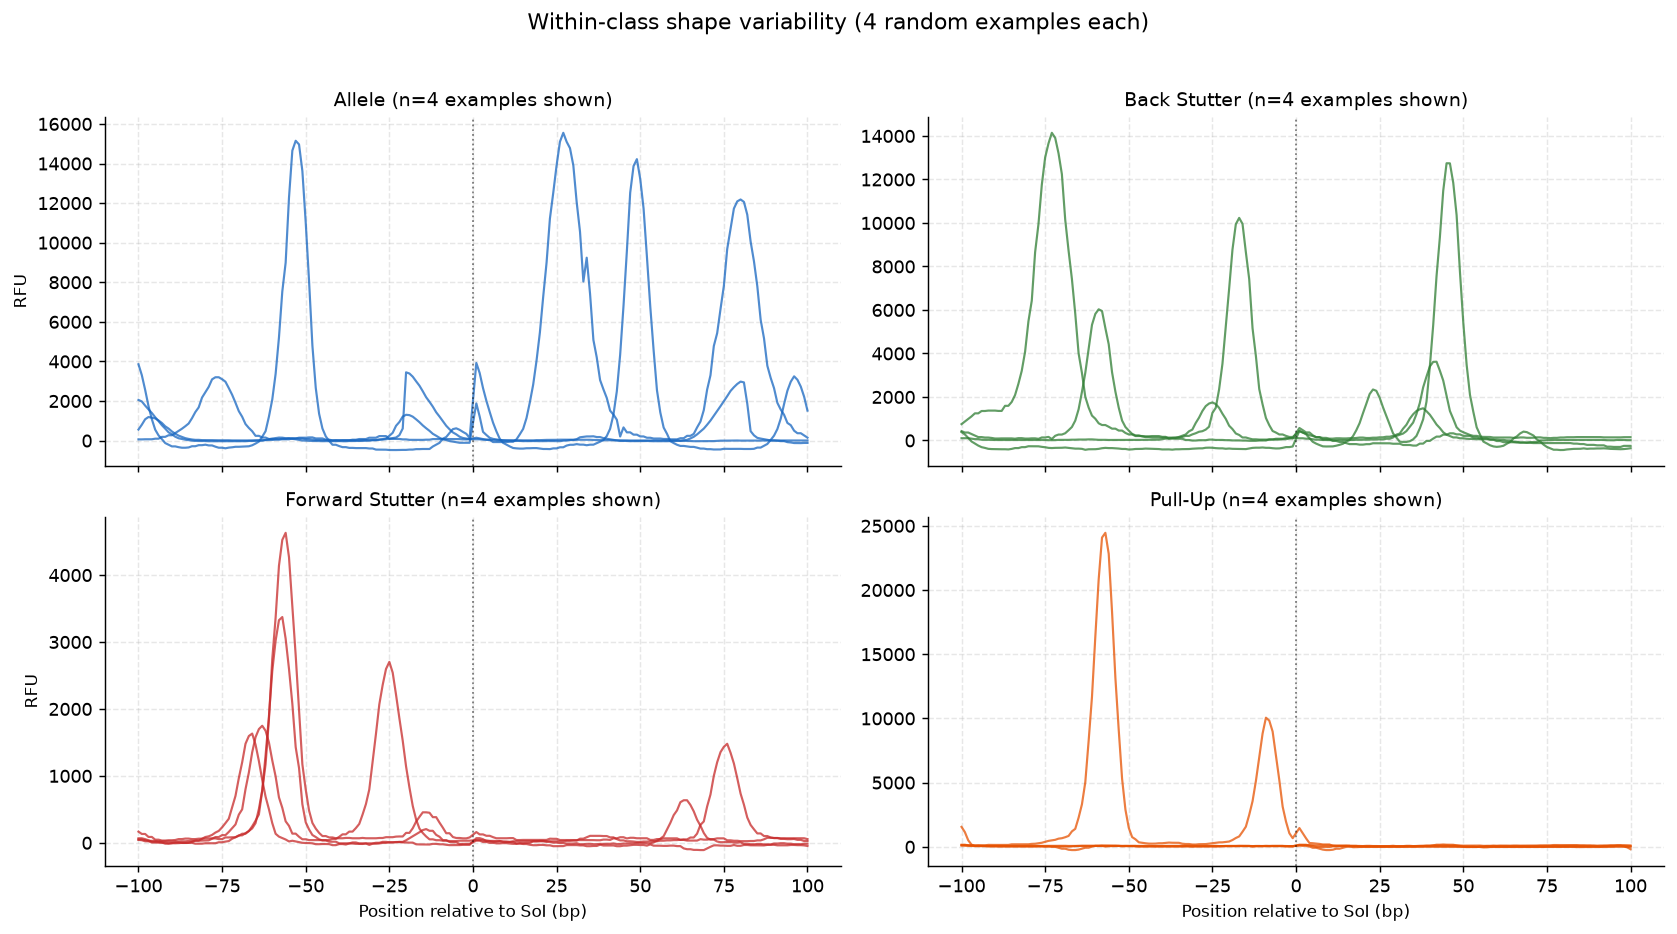

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=False)

for ax, cls in zip(axes.flat, CLASS_ORDER):
    sub = df[df['Classification'] == cls]
    n_samples = min(len(sub), 4)
    subset = sub.sample(n_samples, random_state=42)
    for _, row in subset.iterrows():
        trace = primary_trace(row)
        ax.plot(x_positions, trace, linewidth=1.2, alpha=0.75, color=CLASS_COLORS[cls])
    ax.axvline(0, color='k', linestyle=':', linewidth=1, alpha=0.5)
    ax.set_title(f"{CLASS_LABELS[cls]} (n={n_samples} examples shown)", fontsize=10.5)
    ax.grid(linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

for ax in axes[1]:
    ax.set_xlabel('Position relative to SoI (bp)', fontsize=9.5)
for ax in axes[:, 0]:
    ax.set_ylabel('RFU', fontsize=9.5)

plt.suptitle('Within-class shape variability (4 random examples each)', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_multi_example_per_class.png'), dpi=200, bbox_inches='tight')
plt.show()

## 4  Mean ± std signal profile per class

The average shape for each class, which is what a model implicitly learns to
discriminate between — complements the individual-example plots above.

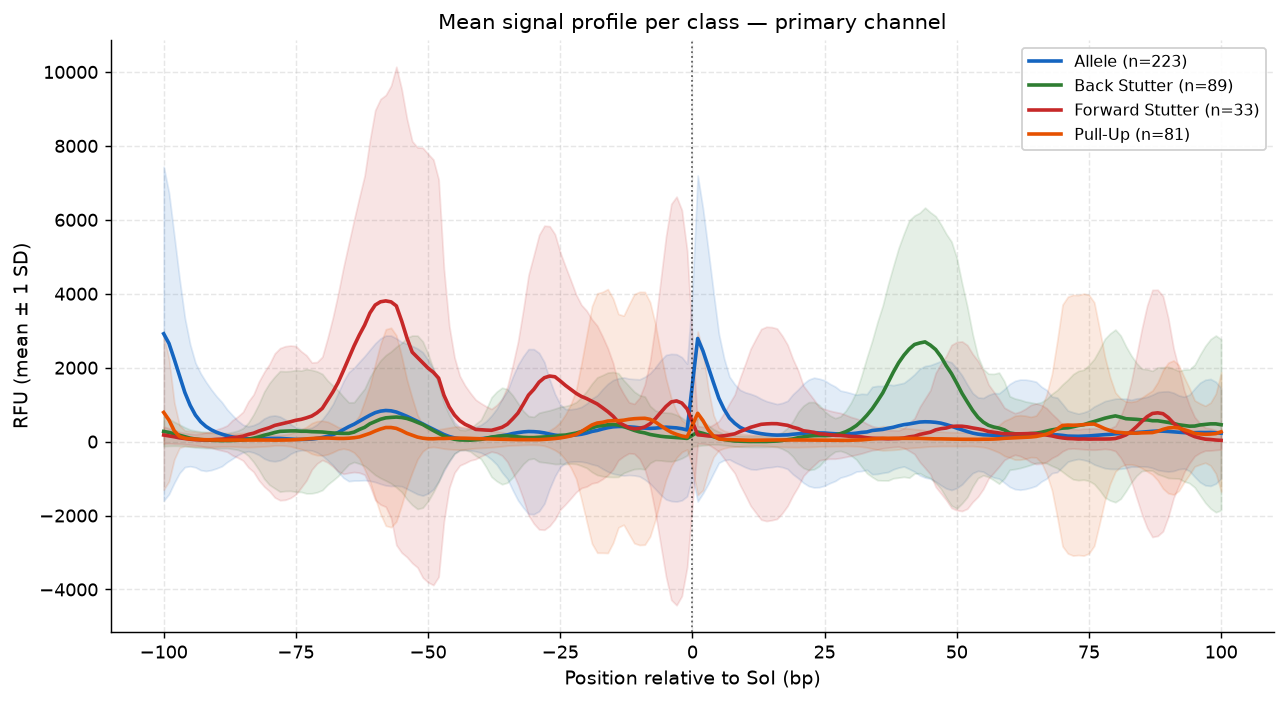

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))

for cls in CLASS_ORDER:
    sub = df[df['Classification'] == cls]
    traces = np.array([primary_trace(row) for _, row in sub.iterrows()])
    mean_trace = traces.mean(axis=0)
    std_trace  = traces.std(axis=0)
    ax.plot(x_positions, mean_trace, color=CLASS_COLORS[cls], linewidth=2,
            label=f'{CLASS_LABELS[cls]} (n={len(sub)})')
    ax.fill_between(x_positions, mean_trace - std_trace, mean_trace + std_trace,
                    color=CLASS_COLORS[cls], alpha=0.12)

ax.axvline(0, color='k', linestyle=':', linewidth=1, alpha=0.6)
ax.set_xlabel('Position relative to SoI (bp)', fontsize=10.5)
ax.set_ylabel('RFU (mean \u00b1 1 SD)', fontsize=10.5)
ax.set_title('Mean signal profile per class — primary channel', fontsize=11.5)
ax.legend(fontsize=9, framealpha=0.9)
ax.grid(linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_class_signal_profile.png'), dpi=200, bbox_inches='tight')
plt.show()

## 5  Allele vs. each artefact class

Direct overlay of a single Allele example against one example from each artefact
class, to visualise the specific shape difference each artefact type introduces.

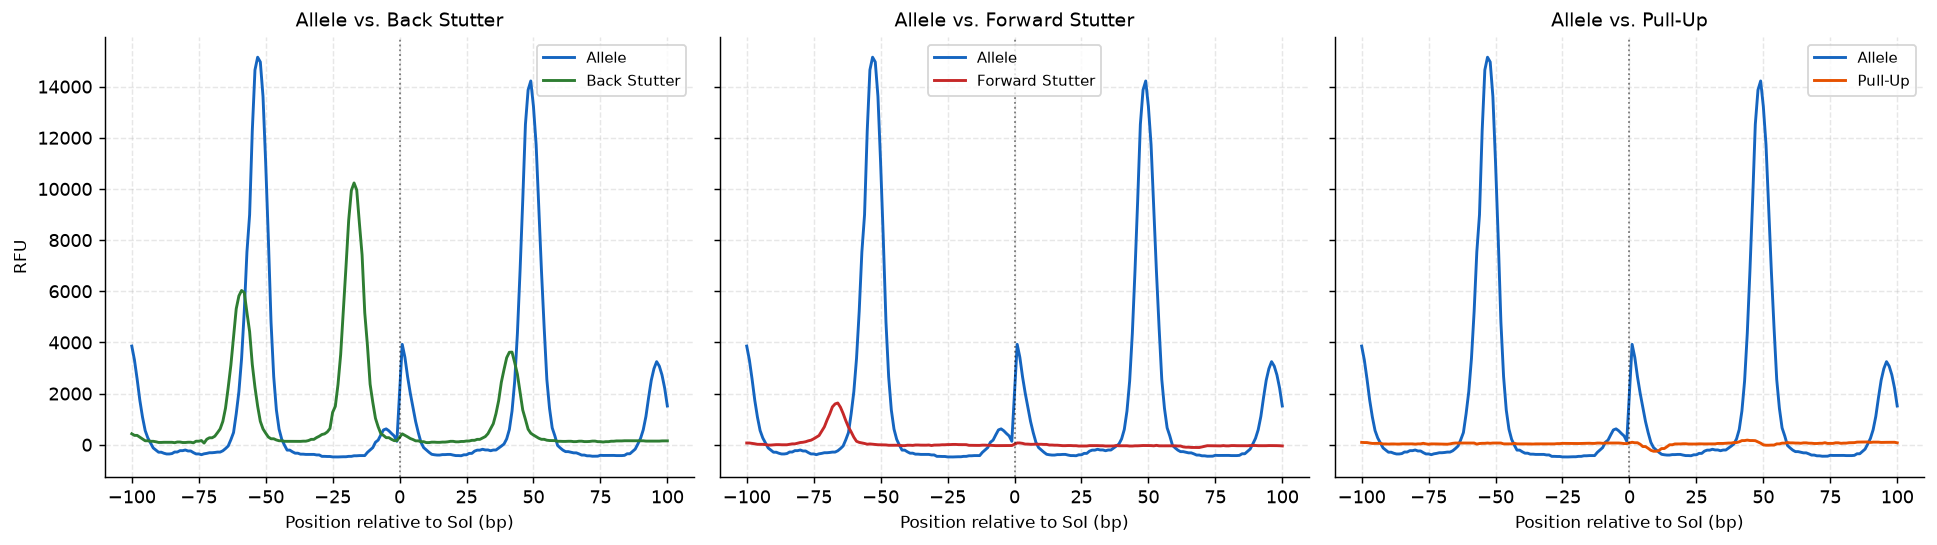

In [ ]:
allele_row = df[df['Classification'] == 'Allele'].sample(1, random_state=42).iloc[0]
allele_trace = primary_trace(allele_row)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)

for ax, cls in zip(axes, ['Back_Stutter', 'Forward_Stutter', 'Pull_Up']):
    other_row = df[df['Classification'] == cls].sample(1, random_state=42).iloc[0]
    other_trace = primary_trace(other_row)
    ax.plot(x_positions, allele_trace, color=CLASS_COLORS['Allele'], linewidth=1.6, label='Allele')
    ax.plot(x_positions, other_trace, color=CLASS_COLORS[cls], linewidth=1.6, label=CLASS_LABELS[cls])
    ax.axvline(0, color='k', linestyle=':', linewidth=1, alpha=0.5)
    ax.set_title(f'Allele vs. {CLASS_LABELS[cls]}', fontsize=10.5)
    ax.set_xlabel('Position relative to SoI (bp)', fontsize=9.5)
    ax.legend(fontsize=8.5)
    ax.grid(linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[0].set_ylabel('RFU', fontsize=9.5)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_allele_vs_artefacts.png'), dpi=200, bbox_inches='tight')
plt.show()

## 6  Cross-channel context (Pull-Up example)

Pull-Up artefacts arise from spectral bleed-through between dye channels — the paper's
SHAP analysis found cross-channel (C1-C5) features specifically useful for this class.
This plots the local context (10bp upstream + SoI + 10bp downstream) in all five
secondary channels for one Pull-Up example, alongside the primary channel.

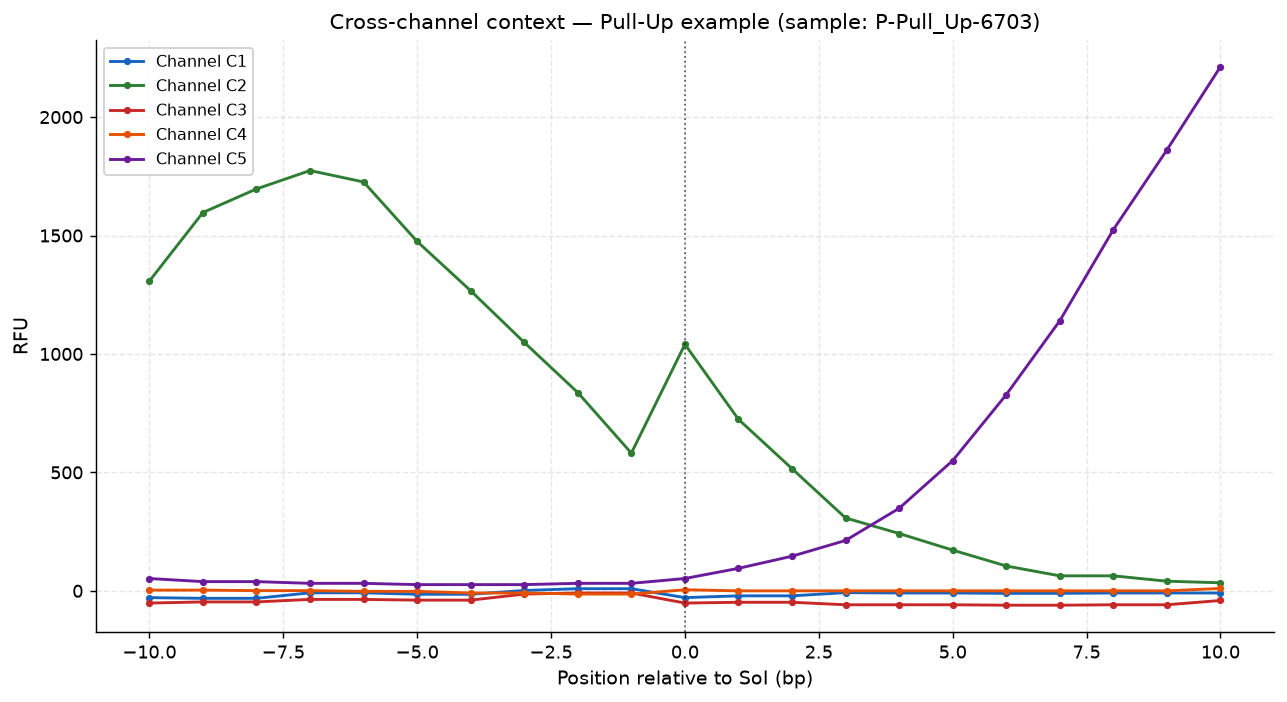

In [ ]:
pullup_row = df[df['Classification'] == 'Pull_Up'].sample(1, random_state=7).iloc[0]

fig, ax = plt.subplots(figsize=(10, 5.5))
x_cc = list(range(-10, 0)) + [0] + list(range(1, 11))

channel_colors = ['#1565C0', '#2E7D32', '#C62828', '#E65100', '#6A1B9A']
for i, (cnum, col) in enumerate(zip(range(1, 6), channel_colors)):
    up = [pullup_row[f'C{cnum}_UpStream_{j}'] for j in range(10, 0, -1)]
    soi = pullup_row[f'C{cnum}']
    down = [pullup_row[f'C{cnum}_DownStream_{j}'] for j in range(1, 11)]
    trace = up + [soi] + down
    ax.plot(x_cc, trace, color=col, linewidth=1.6, marker='o', markersize=3, label=f'Channel C{cnum}')

ax.axvline(0, color='k', linestyle=':', linewidth=1, alpha=0.6)
ax.set_xlabel('Position relative to SoI (bp)', fontsize=10.5)
ax.set_ylabel('RFU', fontsize=10.5)
ax.set_title(f"Cross-channel context — Pull-Up example (sample: {pullup_row['sample']})", fontsize=11.5)
ax.legend(fontsize=9, framealpha=0.9)
ax.grid(linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_crosschannel_pullup.png'), dpi=200, bbox_inches='tight')
plt.show()

## 7  Frequency-domain view (FFT)

One example per class, transformed to the frequency domain, to check whether classes
differ in dominant spatial frequency as well as raw amplitude shape.

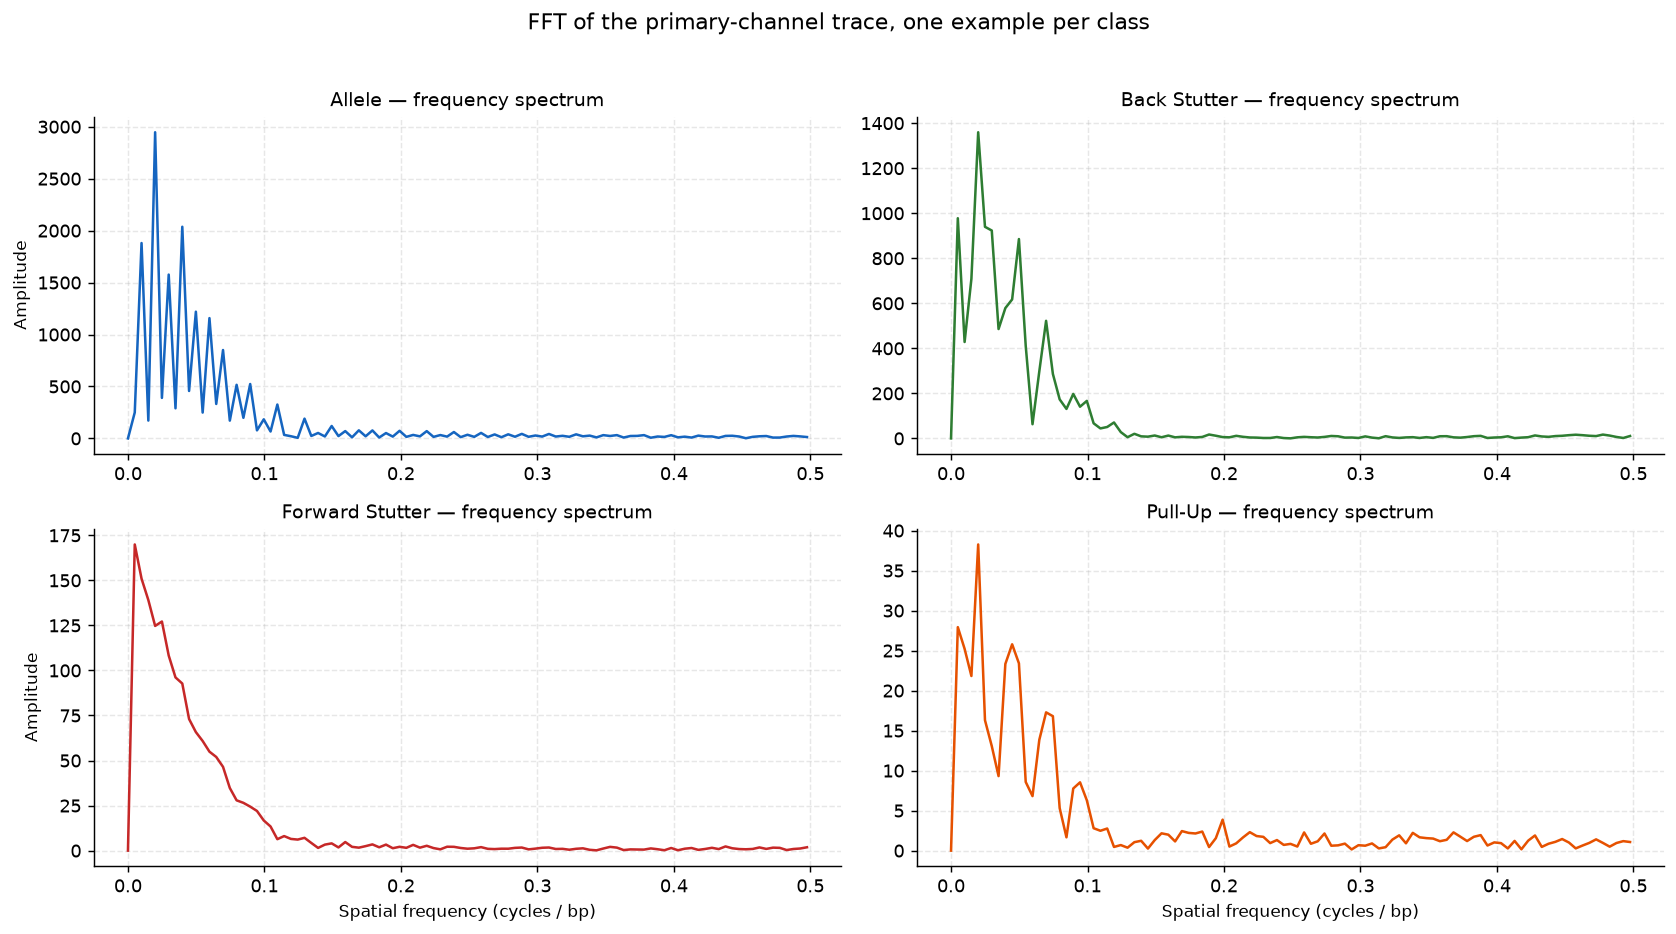

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))

for ax, cls in zip(axes.flat, CLASS_ORDER):
    row = df[df['Classification'] == cls].sample(1, random_state=42).iloc[0]
    trace = primary_trace(row)
    n = len(trace)
    yf = rfft(trace - trace.mean())
    xf = rfftfreq(n, d=1.0)
    amp = np.abs(yf) * 2 / n

    ax.plot(xf, amp, color=CLASS_COLORS[cls], linewidth=1.4)
    ax.set_title(f'{CLASS_LABELS[cls]} — frequency spectrum', fontsize=10.5)
    ax.grid(linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

for ax in axes[1]:
    ax.set_xlabel('Spatial frequency (cycles / bp)', fontsize=9.5)
for ax in axes[:, 0]:
    ax.set_ylabel('Amplitude', fontsize=9.5)

plt.suptitle('FFT of the primary-channel trace, one example per class', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_fft_per_class.png'), dpi=200, bbox_inches='tight')
plt.show()

## 8  PoI distribution

`PoI` (Point of Interest, the peak location) is retained as a 306th feature in the
current pipeline (`Mix_Results_PoI`). This shows its distribution by class.

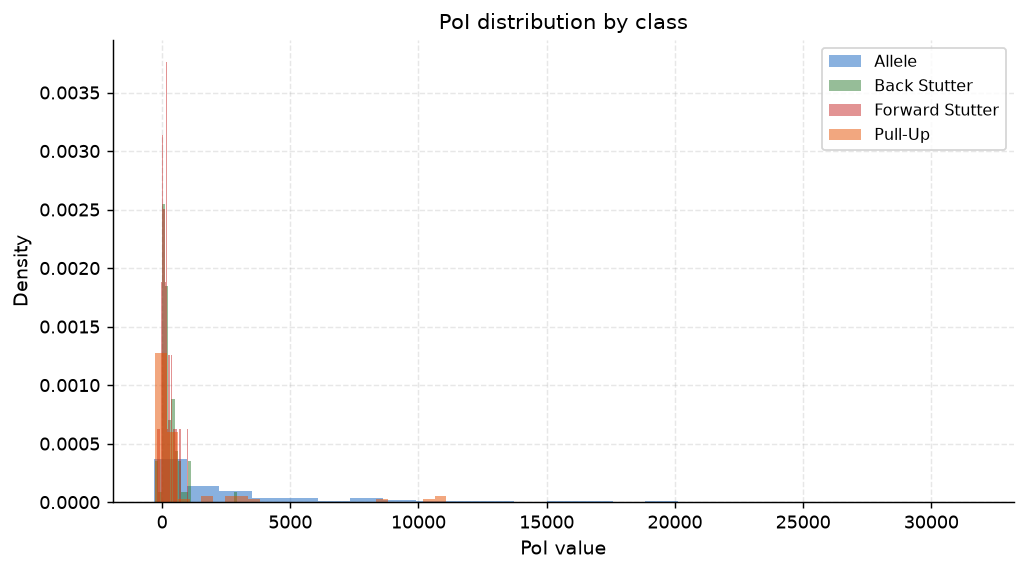

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))

for cls in CLASS_ORDER:
    vals = df[df['Classification'] == cls]['PoI']
    ax.hist(vals, bins=25, alpha=0.5, color=CLASS_COLORS[cls], label=CLASS_LABELS[cls], density=True)

ax.set_xlabel('PoI value', fontsize=10.5)
ax.set_ylabel('Density', fontsize=10.5)
ax.set_title('PoI distribution by class', fontsize=11.5)
ax.legend(fontsize=9)
ax.grid(linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_poi_distribution.png'), dpi=200, bbox_inches='tight')
plt.show()